# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiadas** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

# 🧩 Carga y exploración

**🎯 Objetivo:**  

Tener el **dataset listo en la memoria** y realizar una revisión preliminar.

In [1]:
# Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from scipy.stats import shapiro, levene, ttest_ind, mannwhitneyu, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Visualización previa e información general del conjunto de datos
try:
    df = pd.read_csv('/datasets/landing_experiment.csv')
except:
    df = pd.read_csv('landing_experiment.csv')

In [3]:
# Mostrar las primeras 5 filas
display(df.head(5))

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# Información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


**Descripción del conjunto de datos y validaciones preliminares:**

Tras cargar el dataset `landing_experiment.csv`, compuesto por 40,000 registros y 9 columnas, se observa lo siguiente:

- **Datos ausentes:** El dataset no tiene valores ausentes, las 9 columnas registran exactamente 40,000 valores.


- **Tipos de datos:** La mayoría de los tipos de datos son coherentes, sin embargo, la columna `date` es de tipo `object` y deberá ser convertida a `datetime` para poder realizar análisis temporales adecuados.


- **Consistencia:** Las variables de conversión (`int64`) y gasto (`float64`), tienen los formatos numéricos adecuados para las pruebas estadísticas. 

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario.
- `date` — Fecha en la que el usuario fue expuesto a la página.
- `landing` — Versión de la página mostrada al usuario.
- `region` — Región geográfica del usuario.
- `dispositivo` — Tipo de dispositivo utilizado por el usuario.
- `traffic_source` — Canal por el que llegó el usuario.
- `user_type` — Tipo de usuario según historial previo.
- `converted` — Indica si el usuario realizó una conversión.
- `gasto` — Monto gastado por el usuario (0 si no convirtió).

# Análisis exploratorio y revisión de la calidad de los datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


# Variable `user_id`  

In [5]:
# Verificar cantidad de usuarios únicos frente al total de filas
total_filas = len(df)
usuarios_unicos = df['user_id'].nunique()

print(f"Total de filas en el dataset: {total_filas}")
print(f"Total de usuarios únicos: {usuarios_unicos}")
print(f"Diferencia (posibles registros múltiples por usuario): {total_filas - usuarios_unicos}")

# Validar contaminación de la muestra (usuarios que vieron ambas páginas A y B)
paginas_por_usuario = df.groupby('user_id')['landing'].nunique()
usuarios_cruzados = (paginas_por_usuario > 1).sum()

print(f"\nUsuarios expuestos a ambas versiones (A y B) simultáneamente: {usuarios_cruzados}")

# Ver cuántas veces aparece cada usuario como máximo
max_apariciones = df['user_id'].value_counts().max()
print(f"Número máximo de veces que aparece un mismo usuario: {max_apariciones}")

Total de filas en el dataset: 40000
Total de usuarios únicos: 40000
Diferencia (posibles registros múltiples por usuario): 0

Usuarios expuestos a ambas versiones (A y B) simultáneamente: 0
Número máximo de veces que aparece un mismo usuario: 1


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [7]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


In [8]:
# 1. Convertir "date" a formato "datetime"
df['date'] = pd.to_datetime(df['date'])
print(f"Tipo de dato actualizado para 'date': {df['date'].dtype}")

# 2. Variable landing: Validar el balanceo de la muestra (A vs B)
print("\nDistribución de usuarios por versión de la página (Balanceo):")
conteo_grupos = df['landing'].value_counts()
porcentaje_grupos = df['landing'].value_counts(normalize=True) * 100

balanceo_df = pd.DataFrame({'Usuarios': conteo_grupos, 'Porcentaje (%)': porcentaje_grupos})
display(balanceo_df)

# 3. Variables "converted" y "gasto": validación de reglas lógicas de negocio
print("\nValidación de consistencia entre conversión y gasto:")
errores_gasto = df[(df['converted'] == 0) & (df['gasto'] > 0)]
print(f"-> Usuarios NO convertidos con gasto > 0: {len(errores_gasto)}")

errores_conversion = df[(df['converted'] == 1) & (df['gasto'] <= 0)]
print(f"-> Usuarios SI convertidos con gasto = 0: {len(errores_conversion)}")

Tipo de dato actualizado para 'date': datetime64[ns]

Distribución de usuarios por versión de la página (Balanceo):


,Usuarios,Porcentaje (%)
B,20018,50.045
A,19982,49.955



Validación de consistencia entre conversión y gasto:
-> Usuarios NO convertidos con gasto > 0: 0
-> Usuarios SI convertidos con gasto = 0: 0


# Variable `gasto` 

In [9]:
# Resumen estadístico
display(df['gasto'].describe())

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [10]:
# Resumen estadístico de usuarios que se convirtieron
display(df[df['converted'] == 1]['gasto'].describe())

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [11]:
# Verificar el resto de las variables categóricas
columnas_cat = ['region', 'dispositivo', 'traffic_source', 'user_type']

for col in columnas_cat:
    print(f"\n--- Distribución de {col} ---")
    print(df[col].value_counts())


--- Distribución de region ---
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

--- Distribución de dispositivo ---
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

--- Distribución de traffic_source ---
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

--- Distribución de user_type ---
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


**Revisión de variables categóricas:**

Tras analizar la distribución de las variables cualitativas, se confirma que los datos están limpios y consistentes:

- **Región:** Las cinco regiones (`Norte`, `Centro`, `Sur`, `Occidente` y `Oriente`), están correctamente escritas y sin duplicados por errores tipográficos.

- **Dispositivo:** Solo existen las categorías esperadas `Mobile` y `Desktop`.

- **Fuente de tráfico:** Se distribuye correctamente en `Organic`, `Ads`, `Email` y `Referral`.

- **Tipo de usuario:** Los usuarios están clasificados correctamente como `Nuevo` o `Recurrente`.

Todas las columnas tienen los valores esperados, aún cuando la base de datos es robusta, está lista para comenzar con las pruebas de hipótesis.

# 💰 Comparar el gasto promedio por usuario (página A vs B)

**🎯 Objetivo:** 

Evaluar si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.

In [12]:
# Filtrar solo a los usuarios que convirtieron (gastaron > 0)
df_compradores = df[df['converted'] == 1]

In [13]:
# Separar el gasto por versión de la página
gasto_A = df_compradores[df_compradores['landing'] == 'A']['gasto']
gasto_B = df_compradores[df_compradores['landing'] == 'B']['gasto']

# Verificar cantidad de datos que tiene cada grupo
print(f"Compradores en Página A: {len(gasto_A)}")
print(f"Compradores en Página B: {len(gasto_B)}")
print(f"Gasto promedio Página A: {gasto_A.mean():.2f}")
print(f"Gasto promedio Página B: {gasto_B.mean():.2f}\n")

Compradores en Página A: 2512
Compradores en Página B: 3194
Gasto promedio Página A: 61.09
Gasto promedio Página B: 68.75



## Prueba T de dos muestras independientes (y Mann-Whitney U)

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay diferencia estadísticamente significativa en el gasto promedio por usuario convertido entre la página A y B.
- **Hipótesis alternativa (H₁):** Existe una diferencia estadísticamente significativa en el gasto promedio por usuario convertido entre la página A y B.

In [14]:
# --- Verificación de supuestos ---
# 1. Normalidad (Shapiro-Wilk)
stat_a, p_shapiro_a = shapiro(gasto_A)
stat_b, p_shapiro_b = shapiro(gasto_B)
print(f"Valor p Normalidad (Página A): {p_shapiro_a:.5f}")
print(f"Valor p Normalidad (Página B): {p_shapiro_b:.5f}")

# 2. Homocedasticidad (igualdad de varianzas con Levene)
stat_lev, p_levene = levene(gasto_A, gasto_B)
print(f"Valor p Varianzas (Levene): {p_levene:.5f}")

Valor p Normalidad (Página A): 0.00000
Valor p Normalidad (Página B): 0.00000
Valor p Varianzas (Levene): 0.00000


In [15]:
# Aplicar prueba
alpha = 0.05
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat:0.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico : -9.481
Valor p: 0.00000


In [16]:
# --- Prueba NO paramétrica de respaldo (Mann-Whitney U) ---
# Dado que el gasto en e-commerce rara vez tiene distribución normal, se aplica Mann-Whitney como validación de la prueba t.
u_stat, p_mw = mannwhitneyu(gasto_A, gasto_B)
print(f"Estadistico U: {u_stat:.3f}")
print(f"Valor p (Mann-Whitney): {p_mw:.5f}")

Estadistico U: 3420354.000
Valor p (Mann-Whitney): 0.00000


**📝 Conclusión e interpretación**

**Decisión:** Se rechaza la hipótesis nula (H0), el valor p obtenido es 0.00000 que es estrictamente menor al nivel de significancia *(alpha = 0.05)*.

**Interpretación de negocio:**  
La evidencia estadística demuestra de manera concluyente que el diseño de la página de inicio sí influye en la cantidad de dinero que gastan los clientes. Dado que en el paso previo, se observó que la página B genera un ticket promedio superior **(68.75 vs 61.09 de la página A)**, se recomienda la implementación de la variante B para maximizar el valor económico por usuario.

- **Nota de la metodología empleada:** Las pruebas de normalidad (Shapiro-Wilk) y homocedasticidad (Levene), confirmaron que el gasto no sigue una distribución normal y que presenta varianzas distintas **(valores P = 0.00000)**. Por lo cual: se utilizó la prueba no paramétrica de Mann-Whitney como respaldo, donde se obtuvo el mismo resultado **(valor P = 0.00000)**, y descartando  que el incremento en ventas sea un *Falso-Positivo*.


---


# 📈 Comparar la tasa de conversión entre la página A y B

**🎯 Objetivo:**

Evaluar si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

## Prueba Z para proporciones (Z-test)

**Hipótesis:**

- **Hipótesis nula (H₀):** No hay diferencia estadísticamente significativa en la tasa de conversión entre la página A y la B.
- **Hipótesis alternativa (H₁):** Existe una diferencia estadísticamente significativa en la tasa de conversión entre la página A y la B.

In [17]:
# Número de usuarios convertidos por página
conversiones = df.groupby('landing')['converted'].sum()

# Total de usuarios por página
total_usuarios = df.groupby('landing')['converted'].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", total_usuarios)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [18]:
tasa_A = (conversiones['A'] / total_usuarios['A']) * 100
tasa_B = (conversiones['B'] / total_usuarios['B']) * 100

print(f"Tasa de conversión Página A: {tasa_A:.2f}%")
print(f"Tasa de conversión Página B: {tasa_B:.2f}%")

Tasa de conversión Página A: 12.57%
Tasa de conversión Página B: 15.96%


In [19]:
# Aplicar prueba
exitos = [conversiones['A'], conversiones['B']]
observaciones = [total_usuarios['A'], total_usuarios['B']]

z_stat, p_value = proportions_ztest(exitos, observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat:.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico : -9.677
Valor p: 0.00000


**📝 Conclusión e interpretación**

**Decisión:** Se rechaza la hipótesis nula (H0), el valor p obtenido es 0.00000 que es estrictamente menor al valor de *(alpha = 0.05*).

**Interpretación de negocio:**  
La evidencia estadística confirma de manera significativa que la página B genera un mayor volumen de clientes. *La variante B logró una tasa de conversión de **15.96%**, superando por un margen amplio al **12.57%** proveniente de la variante A*.

- Nota: Al combinar este resultado con el hallazgo de la prueba anterior, se concluye que: **la página B es claramente superior**, ya que no solamente logra que un mayor porcentaje de usuarios decida realizar una compra, sino que también, incentiva a que esos usuarios gasten más en su transacción. La recomendación inmediata es: *implementar la variante B para todo el tráfico.*  

# 🔗 Revisión de la relación entre la fuente de tráfico y la conversión

**🎯 Objetivo:**

Analizar si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

## Prueba Chi-cuadrada de independencia

**Hipótesis:**

- **Hipótesis nula (H₀):** No hay asociación entre la fuente de tráfico y la conversión (variables independientes).
- **Hipótesis alternativa (H₁):** Existe una asociación significativa entre la fuente de tráfico y la conversión (el canal influye en la decisión de compra).

In [20]:
# Construir tabla de contingencia (conteos absolutos)
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'])
display(tabla_trafico)

# Tabla normalizada (porcentajes de conversión por canal)
tabla_trafico_pct = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100
display(tabla_trafico_pct.round(2))

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


converted,0,1
traffic_source,,
Ads,85.26,14.74
Email,85.01,14.99
Organic,86.21,13.79
Referral,86.12,13.88


In [21]:
# Aplicar prueba Chi-cuadrada
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_trafico)

# Visualizar los resultados
print(f"Estadístico Chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico Chi-cuadrado: 8.662
Valor p: 0.03414


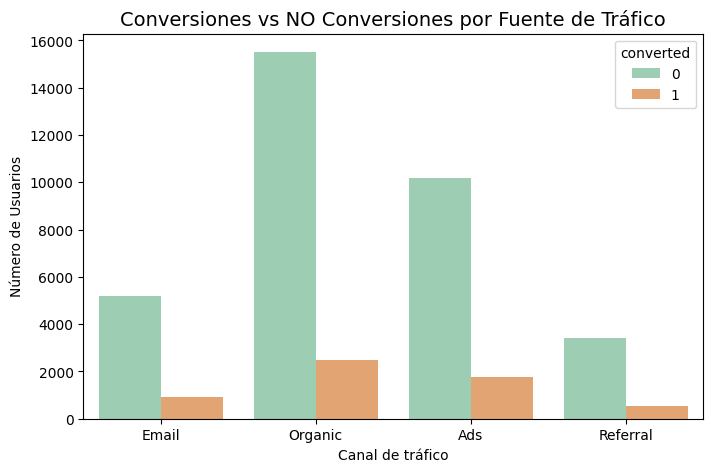

In [22]:
# Visualizar la relación gráficamente para respaldar la conclusión
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='traffic_source', hue='converted', palette=["#95D5B2", "#F4A261"])
plt.title('Conversiones vs NO Conversiones por Fuente de Tráfico', fontsize=14)
plt.xlabel('Canal de tráfico')
plt.ylabel('Número de Usuarios')
plt.show()

**📝 Conclusión e interpretación**

**Decisión:** Se rechaza la hipótesis nula (H0), el valor p obtenido de 0.03414 es menor al nivel de significancia establedido por alpha = 0.05.

**Interpretación de negocio:**  
Existe una asociación estadísticamente significativa entre el canal por el que llegan los usuarios y su decisión de compra. Los canales de marketing directo y de pago muestran una mayor efectividad: el canal de "Email" lidera la conversión con un **14.99%**, seguido muy de cerca por "Ads" con un **14.74%**, mientras que "Organic" con **13.79%** y "Referral" con **13.88%**, presentan tasas inferiores.

- Nota de valor: Aunque la fuente de tráfico sí influye (estadísticamente), la diferencia entre el mejor y el peor canal es de aproximadamente 1.2%, sin embargo, la gráfica revela que "Organic" atrae el mayor volumen total de usuarios con gran diferencia. La recomendación es: *optimizar y aumentar la inversión en retargeting para "Email" y "Ads", mientras se evalúa si la página B logra potenciar ese tráfico de "Organic" masivo que actualmente convierte menos.* 

# 👤 Revisión de la relación entre el tipo de usuario y la conversión

**🎯 Objetivo:**

Analizar si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

## Prueba Chi-cuadrada de independencia

**Hipótesis:**

- **Hipótesis nula (H₀):** No hay asociación entre el tipo de usuario y la conversión (son independientes).
- **Hipótesis alternativa (H₁):** Existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión.

In [23]:
# Construir tabla de contingencia (conteos absolutos)
tabla_usuario = pd.crosstab(df['user_type'], df['converted'])
print("Tabla de contingencia (Conteos):")
display(tabla_usuario)

#Tabla normalizada (porcentajes de conversión por tipo de usuario)
tabla_usuario_pct = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
display(tabla_usuario_pct)

Tabla de contingencia (Conteos):


converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


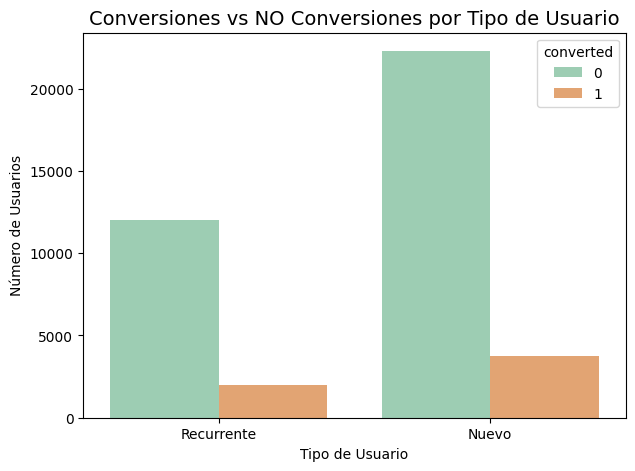

In [24]:
#Visualizar la relación graficamente
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='user_type', hue='converted', palette=["#95D5B2", "#F4A261"])
plt.title('Conversiones vs NO Conversiones por Tipo de Usuario', fontsize=14)
plt.xlabel('Tipo de Usuario')
plt.ylabel('Número de Usuarios')
plt.show()

In [25]:
# Aplicar prueba Chi-cuadrada
chi2_stat_usr, p_value_usr, dof_usr, expected_usr = chi2_contingency(tabla_usuario)

# Visualizar los resultados
print(f"Estadístico Chi-cuadrado: {chi2_stat_usr:.3f}")
print(f"Valor p: {p_value_usr:.5f}")

Estadístico Chi-cuadrado: 0.513
Valor p: 0.47363


**📝 Conclusión e interpretación**

**Decisión:** No se rechaza la hipótesis nula (H0), el valor p obtenido de 0.47363 es muy superior al umbral de significancia establecido por *(alpha = 0.05)*.

**Interpretación de negocio:**  
No existe evidencia estadística para afirmar que el tipo de usuario influya en su probabilidad de compra, al observar los porcentajes, ambos grupos se comportan de manera muy similar frente al experimento, con tasas de conversión de **14.36%** para usuarios nuevos y **14.09%** para usuarios recurrentes.

- Nota de valor: Las estrategias de venta y el diseño de la "landing page" están funcionando de manera transversal. No es necesario gastar recursos técnicos ni presupuesto de marketing en crear versiones segmentadas dependiendo del historial del usuario: *la página B puede desplegarse por igual para todos.*

# 📊 Visualización de los resultados de variables categóricas

**🎯 Objetivos:**

Explorar visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:

- La cantidad absoluta de usuarios que convirtieron y no convirtieron.


- La proporción de usuarios que convirtieron y no convirtieron.

**Relación entre la fuente de tráfico y la conversión**

In [26]:
# Mostrar tabla de contingencia absoluta previamente calculada
print("Volumen absoluto por canal:")
display(tabla_trafico)

Volumen absoluto por canal:


converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


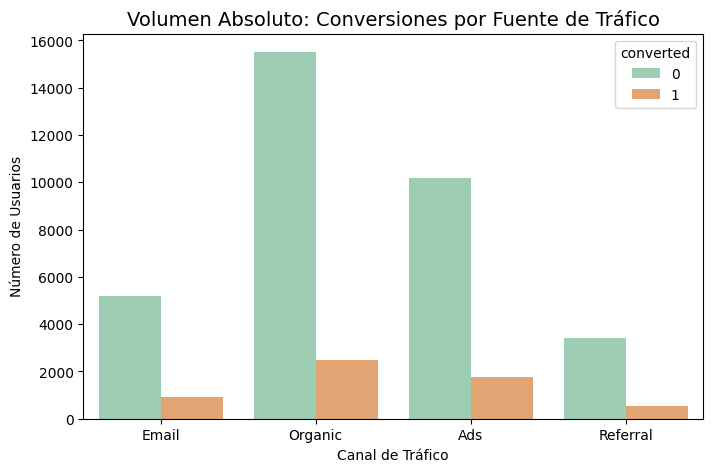

In [27]:
# Gráfica de volumen absoluto (sección 4)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='traffic_source', hue='converted', palette=["#95D5B2", "#F4A261"])
plt.title('Volumen Absoluto: Conversiones por Fuente de Tráfico', fontsize=14)
plt.xlabel('Canal de Tráfico')
plt.ylabel('Número de Usuarios')
plt.show()

✍️ **Análisis de volumen absoluto:**

La gráfica revela que la fuente de tráfico `Organic` es, por mucho, la que atrae más cantidad de usuarios totales a la página, seguida por `Ads`. El canal de referidos (`Referral`) es el que menor volumen aporta al negocio.

In [28]:
# Mostrar tabla de proporciones previamente calculada
print("Proporciones de conversión por canal (%):")
display(tabla_trafico_pct.round(2))

Proporciones de conversión por canal (%):


converted,0,1
traffic_source,,
Ads,85.26,14.74
Email,85.01,14.99
Organic,86.21,13.79
Referral,86.12,13.88


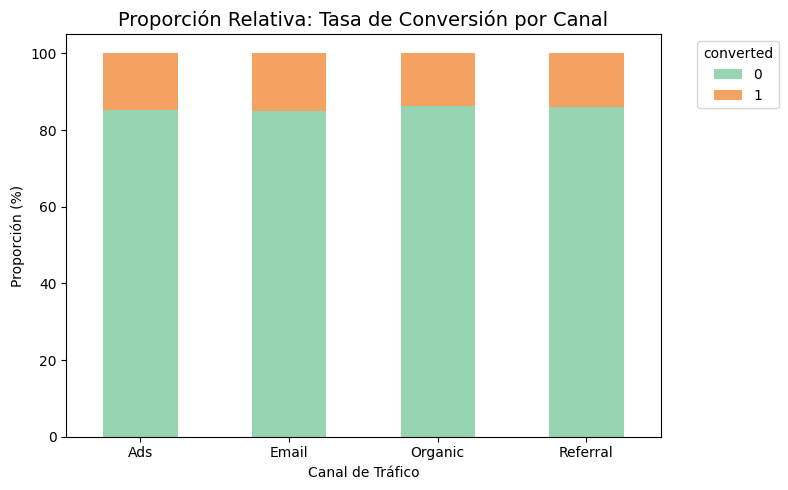

In [29]:
# Gráfica de barras apiladas al 100%
tabla_trafico_pct.plot(kind='bar', stacked=True, figsize=(8, 5), color=["#95D5B2", "#F4A261"])
plt.title('Proporción Relativa: Tasa de Conversión por Canal', fontsize=14)
plt.xlabel('Canal de Tráfico')
plt.ylabel('Proporción (%)')
plt.legend(title='converted', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

✍️ **Análisis de proporción:**

Al normalizar los datos al 100%, la perspectiva cambia. Se hace evidente visualmente que aunque `Organic` aporta más volumen, los canales de `Email` y `Ads` tienen una franja naranja correspondiente a la conversión que es proporcionalmente más gruesa, confirmando estadísticamente que son los canales más eficientes para cerrar compras.

**Relación entre el tipo de usuario y la conversión**

In [30]:
# Mostrar tabla de contingencia absoluta
print("Volumen absoluto por tipo de usuario:")
display(tabla_usuario)

Volumen absoluto por tipo de usuario:


converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


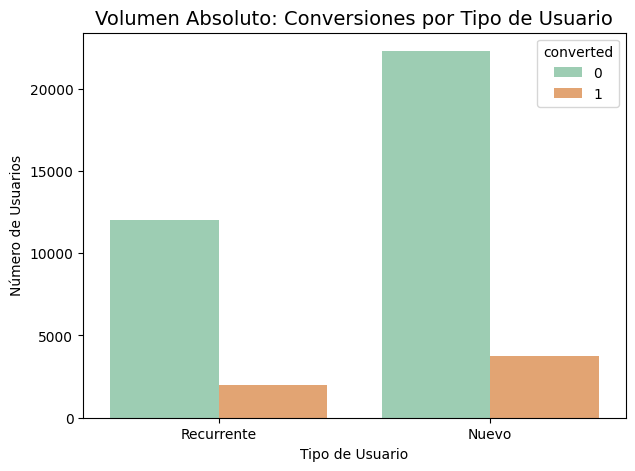

In [31]:
# Gráfica de volumen absoluto (Reciclamos la del paso 5)
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='user_type', hue='converted', palette=["#95D5B2", "#F4A261"])
plt.title('Volumen Absoluto: Conversiones por Tipo de Usuario', fontsize=14)
plt.xlabel('Tipo de Usuario')
plt.ylabel('Número de Usuarios')
plt.show()

✍️ **Análisis de volumen absoluto:**

Se observa que el volumen de usuarios clasificados como `Nuevo`, es considerablemente mayor (casi dos veces) que el de los usuarios con perfil `Recurrente`. El experimento tuvo una mayor exposición ante tráfico de primera vez.

In [32]:
# Mostrar tabla de proporciones
print("Proporciones de conversión por tipo de usuario (%):")
display(tabla_usuario_pct.round(2))

Proporciones de conversión por tipo de usuario (%):


converted,0,1
user_type,,
Nuevo,85.64,14.36
Recurrente,85.91,14.09


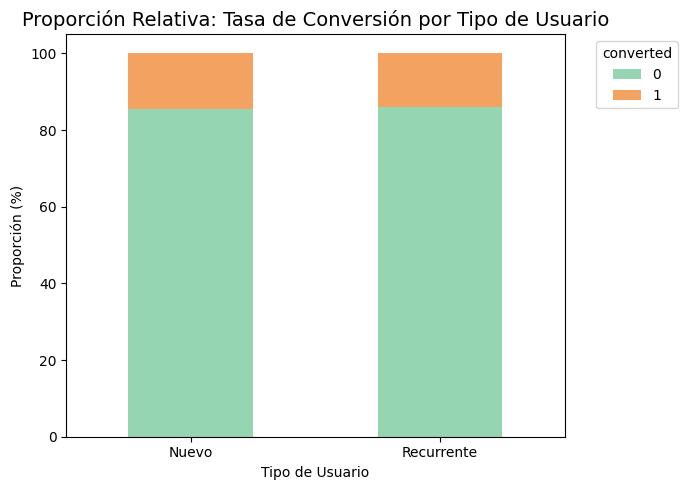

In [33]:
# Gráfica de barras apiladas al 100%
tabla_usuario_pct.plot(kind='bar', stacked=True, figsize=(7, 5), color=["#95D5B2", "#F4A261"])
plt.title('Proporción Relativa: Tasa de Conversión por Tipo de Usuario', fontsize=14)
plt.xlabel('Tipo de Usuario')
plt.ylabel('Proporción (%)')
plt.legend(title='converted', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

✍️ **Análisis de propoción:** 

Al observar las proporciones apiladas, las barras son visualmente idénticas. La franja de conversión representa aprox. el **14%** en ambos grupos, lo que respalda gráficamente la conclusión estadística: *el perfil del usuario no afecta su probabilidad final de realizar una compra.*

# 🧩 Insight Ejecutivo

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

---

# 🌟 Insight Ejecutivo basado en el Experimento A/B

### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Observación 1: La variante B generó un ticket promedio de **68.75**, superando claramente los **61.09** obtenidos por la variante A.
  
- Observación 2: La prueba estadística no paramétrica (U de Mann-Whitney) validó que esta diferencia no es un producto al azar, arrojando una alta significancia estadística (p = 0.00000).

- **Interpretación:** El rediseño estructural de la página B es altamente efectivo para incentivar *upselling* o compras de mayor volumen, logrando que los clientes gasten más dinero en cada transacción una vez que toman la decisión de comprar.

---

**Tasa de conversión:** 
- Observación 1: La variante B alcanzó una tasa de conversión global del **15.96%** superando por un margen amplio al **12.57%** generado por la variante A.
  
- Observación 2: La prueba Z para propociones, confirmó de manera concluyente (p = 0.00000) que el incremento en la tasa de conversión es estadísticamente significativo.

- **Interpretación:**
La página B es superior en todo el embudo de ventas. No solamente logra tickets de compra más altos, sino que es sustancialmente mejor para retener el interés del usuario y convencerlo de concretar una transacción.

---

### 📊 **Segmentación por fuente de tráfico**
- Observación: Existe una dependencia estadísticamente significativa (p = 0.03414) entre la decisión de compra y el canal de origen. "Email" con **14.99%** y "Ads" con **14.74%** lideran las tasas de conversión, mientras que "Organic" con **13.79%** reporta la tasa más baja a pesar de ser el canal que aporta el mayor volumen absoluto de visitantes.

- **Interpretación:** 
Los canales de marketing directo y de pago atraen a un perfil de usuario con una mayor intención de compra previa. Por otra parte, el canal "Organic" es el motor principal de tráfico, solamente que atrae a un público más exploratorio que requiere un empuje extra para convertir.

 ---

### 📊 **Segmentación por tipo de usuario**
- Observación: Las tasas de conversión entre usuarios "Nuevos" con **14.36%** y "Recurrentes" con **14.09%** son virtualmente idénticas. La prueba Chi-cuadrada (p= 0.47363) descarta cualquier asociación significativa entre estas variables.
  
- **Interpretación:**
El comportamiento transaccional dentro del experimento es independiente del historial previo del cliente. La plataforma es igual de intuitiva y persuasiva tanto para captar primeras compras como para facilitar la retención y recompra.

---

### 💡 **Recomendaciones de negocio:** 
- **Desplegar la variante B al 100% del tráfico inmediatamente:** La evidencia estadística demuestra que la página B domina tanto en volumen de conversiones como en el ticket promedio generado. Retrasar su implementación generalizada, representa un costo de oportunidad directo en los ingresos de la compañía.
     
- **Estandarizar la plataforma sin segmentación por tipo de usuario:** Dado que no existe una diferencia significativa en cómo convierten los usuarios nuevos frente a los recurrentes, no es necesario invertir recursos técnicos o presupuesto en desarrollar experiencias separadas según el historial del cliente; la página B funciona como una solución universal efectiva.
     
- **Capitalizar el tráfico orgánico masivo mediante "retargeting":** El canal "Organic" trae la mayor cantidad de usuarios potenciales, pero en su conversión es menor. Se sugiere implementar campañas de "Ads" y de "Email", dirigidas específicamente a los usuarios orgánicos que visitaron la página B pero abandonaron sin comprar, para así poder maximizar el retorno de ese volumen masivo.   